# 2x2 MMI — FDTD/EME Hybrid Simulation

HybridSolver is a generic N-section cascade: any solver type, in any order, any count >= 2.
Here we chain three sections —

    [input section]  ->  [body section]  ->  [output section]

— each independently configurable as FDTD or EME via the METHOD switches below.
HybridSolver itself has no idea any of these are FDTD/EME or that the device is an MMI; it
only knows each solver implements `solve_section()` and combines the resulting per-section
modal transfer matrices by matrix-chain multiplication. The MMI-specific geometry (tapers,
body, branches) lives entirely in MMI's `section_prisms`/`section_gds`/`width_at`/`center_at`
methods.

Unlike the 1x2 splitter, a 2x2 has two ports on *both* sides sitting close together
(waveguide_offset = 1.5 um), so both the input and output FDTD sections use
`half_domain_aperture` to isolate the excited/measured port from its neighbor. The top
input is excited (`input_idx=1`); the top output is the "bar" port (`output_idx=1`) and the
bottom output the "cross" port (`output_idx=0`).

One hybrid pass: the output section is NEVER separately simulated — by mirror symmetry +
reciprocity, `output_idx=k` is the x-mirror of `input_idx=k`, so the bar/cross output
matrices are just the input matrices transposed. With `SYMMETRIC_MODE_REUSE` (default on),
the bottom-arm matrix `M_in0` is ALSO not separately simulated: launching top vs. bottom arm
is itself a mirror operation, so each body mode's coefficient either matches or flips sign
between the two launches (even/odd mode symmetry) — see the `MODE_SIGNS` comment below for
how that sign vector was measured. This drops the FDTD count from 2 to 1. Set
`SYMMETRIC_MODE_REUSE=False` to fall back to simulating both arms directly.

The multimode-section length sweep rides the same pass: the EME body is a uniform mm_width
slab, so `EMESolver.solve_section_length_sweep()` solves its modes once per wavelength and
applies each swept length as an analytic propagation phase.

Both savings are **declared** to HybridSolver rather than hand-rolled. The bar path is an
ordinary `mirror_pairs={2: 0}`. The cross path — which pairs one arm's transposed matrix
with the other arm's excitation, and which `solve()`'s one-call contract genuinely could not
express — is a `MirrorSpec` carrying the parity vector:

    mirror_pairs={2: MirrorSpec(section=0,
                                partner_kwargs={"input_idx": 0},
                                mode_signs=MODE_SIGNS)}

so the whole two-excitation response still comes from ONE FDTD simulation, now through the
supported API. Both declarations are re-validated geometrically on every call, which the
hand-rolled einsum this replaced never was — and because each call now carries a single
excitation, `calibrate_body_neff` works here, which the hand-rolled cascade could not use
at all.

In [1]:
import os
import numpy as np
import matplotlib

import matplotlib.pyplot as plt

from beef import MMI, EMESolver, FDTDSolver, HybridSolver, MirrorSpec, SMatrix, SOI_220, plot_hybrid_geometry, plot_beta_calibration, plot_hybrid_body_fields, port_phases

_HERE = os.getcwd()
output_dir = os.path.abspath(os.path.join(_HERE, "..", "..", "..", "..", "example_output", "mmi_2x2", "mmi_2x2_hybrid"))
os.makedirs(output_dir, exist_ok=True)
save_dir = os.path.abspath(os.path.join(_HERE, "..", "..", "..", "..", "example_sim_cache"))

In [2]:
# ---------------------------------------------------------------------------
# Global simulation parameters
# ---------------------------------------------------------------------------
RESOLUTION = 40.0   # mesh resolution (pixels/µm) — used by both the EME and FDTD sub-solvers
WL_MIN = 1.530      # wavelength sweep start (µm)
WL_MAX = 1.565      # wavelength sweep end (µm)
N_WL = 11           # number of wavelength points

CALIBRATE_BODY = True    # propagate the EME body on the FDTD's own measured beta
SYMMETRIC_MODE_REUSE = True   # derive M_in0 from M_in1 via MODE_SIGNS instead of a 2nd FDTD run

In [3]:
# ---------------------------------------------------------------------------
# 0. Simulation method per section — HybridSolver is solver-agnostic (any
#    mix of FDTDSolver/EMESolver, in any order), so each of the three
#    sections can independently be "fdtd" or "eme".
# ---------------------------------------------------------------------------
INPUT_METHOD = "fdtd"    # "fdtd" or "eme"
BODY_METHOD = "eme"      # "fdtd" or "eme"
OUTPUT_METHOD = "fdtd"   # "fdtd" or "eme"

In [4]:
# ---------------------------------------------------------------------------
# 1. Geometry
# ---------------------------------------------------------------------------
mmi = MMI(
    n_inputs=2,             # 2x2 splitter
    n_outputs=2,
    mm_length=28.0,
    mm_width=2.8,
    waveguide_width=0.45,
    taper_length=4.0,
    taper_width=1.3,
    waveguide_offset=1.5,
    waveguide_height=0.22,  # SOI_220
)
print(f"MMI total length: {mmi.total_length:.2f} µm")
print(f"Input ports at y = {mmi.input_ys} µm; outputs at y = {mmi.output_ys} µm")

MMI total length: 36.00 µm
Input ports at y = [-0.75, 0.75] µm; outputs at y = [-0.75, 0.75] µm


In [5]:
# ---------------------------------------------------------------------------
# 2. Configure sub-solvers — one per section, per the METHOD switches above.
#
#    input section  : input access waveguide + input taper + a bit of the
#                      MMI body (enough for a clean interface monitor past
#                      the taper/body cross-section discontinuity)
#    body section   : propagates N modes through the remaining rectangular
#                      MMI body
#    output section : the mirror image of the input section, one instance
#                      per output port
# ---------------------------------------------------------------------------

_fdtd_common = dict(
    res=RESOLUTION,
    sim_width=5.0,
    sim_height=1.5,
    dpml=0.5,
    source_margin=0.0,
    monitor_margin=0.25,
    three_d=True,       # full 3-D FDTD: real 220 nm Si core in oxide, PML on all six faces
    material_stack=SOI_220,
    decay_tol=1e-11,
)

N_MODES = 14   # modes carried at the two input/output <-> body interfaces.
               # Was 15: band 14 (n_eff 1.4078) sits below the 1.4443 cladding
               # index -- a radiation mode, dropped at no cost.
               # mmi_2x2_validation.md gap 3.

# Per-mode sign relating the bottom-arm launch to the top-arm launch
# (M_in0[m] = MODE_SIGNS[m] * M_in1[m]), measured once against a real
# 2-FDTD-arm run (cache_only, both directions, max relative residual on the
# dominant modes ~1e-4; weak/near-cutoff modes 7-9/11/12 are noisier
# individually but negligible in the final T_bar/T_cross, verified <=1.1e-4
# relative across the full 201-length x 11-wavelength grid). Fixed geometric
# property of the mirror-symmetric cross-section -- not resolution/
# wavelength/length dependent. Re-derive by setting SYMMETRIC_MODE_REUSE =
# False if the geometry changes.
MODE_SIGNS = np.array([1, -1, 1, -1, 1, -1, 1, -1, -1, -1, -1, 1, -1, 1])

# Both the input and output ports have a neighbor waveguide_offset = 1.5 µm
# away that is drawn in the same section (all branches are always physically
# present). half_domain_aperture confines each section's source/norm aperture
# to the near half of the domain (from the shared y=0 symmetry axis to the
# near PML edge), structurally excluding the opposite branch.

def make_section_solver(method: str, half_domain_aperture: bool = False):
    """Build a solver for one hybrid section. Both FDTDSolver and EMESolver
    implement the same solve_section() interface, so either can fill any
    slot in the chain — num_modes/num_cells/lengths on EMESolver only
    matter for its full-device solve()/solve_sweep(), not solve_section(),
    so placeholder values are fine here."""
    if method == "fdtd":
        kwargs = dict(_fdtd_common)
        kwargs["half_domain_aperture"] = half_domain_aperture
        return FDTDSolver(**kwargs)
    if method == "eme":
        return EMESolver(
            num_modes=[N_MODES], num_cells=[1], lengths=[1.0],
            oxide_width=5.0, oxide_height=1.5, res=RESOLUTION, material_stack=SOI_220,
            mode_solver="meep",  # matches FDTDSolver's own eigenmode basis in this hybrid chain
        )
    raise ValueError(f"unknown method {method!r}, expected 'fdtd' or 'eme'")

# Both sides have two closely-spaced ports, so both the input and output
# sections need the narrower half-domain aperture (unlike the 1×2, whose lone
# input keeps the full sim_width). output_solver is never actually run — the
# output section's transfer matrices are mirror-derived from the input
# section's (see module docstring) — it exists only so the HybridSolver
# below labels the section map correctly in the geometry plot.
input_solver = make_section_solver(INPUT_METHOD, half_domain_aperture=True)
body_solver = make_section_solver(BODY_METHOD)
output_solver = make_section_solver(OUTPUT_METHOD, half_domain_aperture=True)

In [6]:
# ---------------------------------------------------------------------------
# 3. Build HybridSolver — a generic 3-section chain here, but HybridSolver
#    itself works with any solver list of length >= 2, in any order.
# ---------------------------------------------------------------------------
half_body = mmi.mm_length / 2
half_total = mmi.total_length / 2
body_stub = 0.25   # µm of MMI body folded into each FDTD section, past the
                   # taper/body cross-section discontinuity

boundaries = [
    -half_total,               # physical input port (input taper tip)
    -half_body + body_stub,    # input section <-> body section interface
    +half_body - body_stub,    # body section <-> output section interface
    +half_total,               # physical output port (output taper tip)
]
interface_modes = [N_MODES, N_MODES]

# Multimode-length sweep grid. The geometry stays built at the nominal
# mm_length — only the body cross-section (a length-independent mm_width
# slab) feeds the one EME mode solve, and each swept length is applied
# analytically. Each FDTD section folds body_stub µm of MMI body into
# itself, so the EME body section's physical length is mm_length minus
# both stubs.
mm_lengths = np.linspace(16.0, 40.0, 201)   # µm; nominal 28.0 lands exactly on index 100
body_lengths = mm_lengths - 2 * body_stub   # EME body section's physical length

# One HybridSolver per excitation configuration. Each call carries a single
# excitation, which satisfies solve()'s one-call contract — so
# calibrate_body_neff works here, where the hand-rolled cascade this replaces
# could never use it (the flag only fires inside _solve_sections()).
#
# The two differ ONLY in how section 2 is declared:
#
#   bar   — section 2 measures the top output, the x-mirror of the top input
#           that section 0 was excited on. An ordinary mirror pair.
#   cross — section 2 measures the BOTTOM output. That is the x-mirror of the
#           bottom INPUT, which section 0 was not excited on. MirrorSpec says
#           so explicitly: reuse section 0, but reinterpreted as the other arm
#           (partner_kwargs) via the measured parity vector (mode_signs).
#
# Both are re-validated against the geometry on every call. The cross
# declaration is checked twice over: that section 2 is the x-mirror of
# section 0 under partner_kwargs, AND that section 0's two arms really are
# transverse mirror images — without the second check partner_kwargs would be
# an unchecked way to pair any two unrelated branches.
_shared = dict(solvers=[input_solver, body_solver, output_solver],
               boundaries=boundaries,
               interface_modes=interface_modes,
               calibrate_body_neff=CALIBRATE_BODY)

if SYMMETRIC_MODE_REUSE:
    cross_mirror = {2: MirrorSpec(section=0,
                                  partner_kwargs={"input_idx": 0},
                                  mode_signs=MODE_SIGNS)}
    cross_kwargs = {0: {"input_idx": 1}, 2: {"output_idx": 0}}
else:
    # Fall back to simulating the bottom arm for real: section 0 is excited
    # on input_idx=0, and section 2 is then its plain x-mirror. This is the
    # 2-FDTD-run configuration, and it is what re-derives MODE_SIGNS below.
    cross_mirror = {2: 0}
    cross_kwargs = {0: {"input_idx": 0}, 2: {"output_idx": 0}}

hybrid_bar = HybridSolver(mirror_pairs={2: 0}, **_shared)
hybrid_cross = HybridSolver(mirror_pairs=cross_mirror, **_shared)

# Kept under the old name for the geometry plot below, which only reads
# boundaries/solvers/mirror_pairs off it.
hybrid = hybrid_bar

bar_kwargs = {0: {"input_idx": 1}, 2: {"output_idx": 1}}

Geometry plot saved → /Users/jhiesener/Documents/Research/duty/example_output/mmi_2x2/mmi_2x2_hybrid/geometry_hybrid.png
Sub-region plots saved → /Users/jhiesener/Documents/Research/duty/example_output/mmi_2x2/mmi_2x2_hybrid/sections/


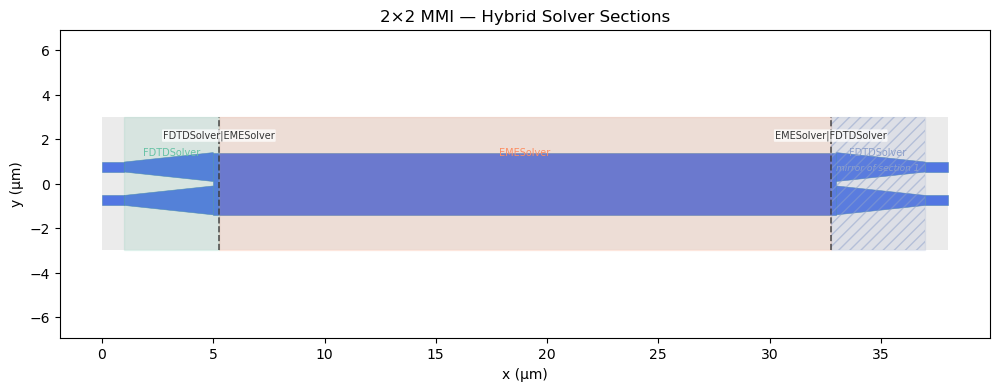

In [7]:
# ---------------------------------------------------------------------------
# 4. Geometry plot — shows which solver covers which section
# ---------------------------------------------------------------------------
plot_hybrid_geometry(
    mmi, solver=hybrid,
    in_modes=1, out_modes=1,
    title="2×2 MMI — Hybrid Solver Sections",
    output_path=os.path.join(output_dir, "geometry_hybrid.png"),
    sub_region_dir=os.path.join(output_dir, "sections"),
    sub_region_show_pml=True,
    sub_region_show_eme_detail=True,
    # Both input arms shown for reference; "in_bot" is only actually
    # simulated in step 5 when SYMMETRIC_MODE_REUSE=False (see there). Output
    # section (index 2) is the x-mirror of the input section either way, so
    # it gets no sub-region plot — hatched/labeled as mirrored above instead.
    sub_region_configs=[
        ("in_top", {0: {"input_idx": 1}}, {2: 0}),
        ("in_bot", {0: {"input_idx": 0}}, {2: 0}),
    ],
)
print(f"Geometry plot saved → {output_dir}/geometry_hybrid.png")
print(f"Sub-region plots saved → {output_dir}/sections/")

In [ ]:
# ---------------------------------------------------------------------------
# 5. Run the hybrid pass. Output section: never simulated (mirror symmetry,
#    see module docstring). Body: 1 EME mode-solve/wavelength, length-swept
#    analytically. Input: 1 FDTD solve (SYMMETRIC_MODE_REUSE) or 2 (both
#    arms simulated directly).
# ---------------------------------------------------------------------------
wavelengths = np.linspace(WL_MIN, WL_MAX, N_WL)
print(f"\nHybrid sweep: {wavelengths[0]:.3f} – {wavelengths[-1]:.3f} µm "
      f"({len(wavelengths)} pts, {N_MODES} interface modes), "
      f"mm_length {mm_lengths[0]:.1f} – {mm_lengths[-1]:.1f} µm "
      f"({len(mm_lengths)} pts)\n")

# ONE shared cache across both excitations. Section 0's geometry_kwargs are
# identical between the bar and cross calls (both excite the top arm), so it
# is simulated exactly once; the body likewise. Section 2 is never simulated
# in either call — mirror_pairs short-circuits it. Total: 1 FDTD input solve
# + 1 EME body solve, the same count the hand-rolled cascade achieved, now
# with the symmetry arguments declared and geometrically checked instead of
# implied by the shape of an einsum.
#
# calibrate_body_neff=True on both solvers propagates the body on the FDTD's
# own measured beta (see EMESolver._override_neff). It is the same quantity
# the hand-rolled path computed by calling section_mode_beta_details()
# itself, over the same span with the same n_modes — so this is an API
# change, not a physics one, and the numbers must not move.
section_cache = {}

coeffs_bar = hybrid_bar.solve_length_sweep(
    mmi, wavelengths, body_lengths, sweep_section=1,
    geometry_kwargs=bar_kwargs, cache=section_cache, save_dir=save_dir,
)    # [n_L, n_wl, 1, 1]
coeffs_cross = hybrid_cross.solve_length_sweep(
    mmi, wavelengths, body_lengths, sweep_section=1,
    geometry_kwargs=cross_kwargs, cache=section_cache, save_dir=save_dir,
)    # [n_L, n_wl, 1, 1]

if CALIBRATE_BODY:
    # The measurement behind the body's propagation constants. Only the bar
    # solver holds it: the cross call's body section came from the shared
    # cache, so its own calibration never re-ran (by design — a cache hit
    # means the matrix this pass used IS the one that calibration produced).
    calibration = hybrid_bar.last_calibrations[1]

    # What the calibration actually simulated, and whether each cell's phase
    # is really linear in length. The residual guard reduces that to one
    # number per cell and only raises past 0.1 rad, so a marginal fit passes
    # silently and is invisible in `beta` — these plots are where it shows.
    # Free: no extra simulation, just the data the call already produced.
    plot_beta_calibration(
        calibration, mmi, input_solver,
        os.path.join(output_dir, "calibration"),
        monitor_center=0.0, monitor_size=input_solver.sim_width,
    )
    print(f"Calibration plots saved → {output_dir}/calibration/"
          f" (geometry/ + fits/)")

if not SYMMETRIC_MODE_REUSE:
    # Re-derive MODE_SIGNS. Both arms were really simulated in this
    # configuration, so the implied parity vector can be read straight off
    # the two input-section matrices the two passes used — no third solve.
    _m_top = hybrid_bar.last_section_matrices[0][:, :, 0]      # [n_wl, N_MODES]
    _m_bot = hybrid_cross.last_section_matrices[0][:, :, 0]
    _ratio = _m_bot / np.where(np.abs(_m_top) > 0, _m_top, np.nan)
    _implied = np.sign(np.real(np.nanmean(_ratio, axis=0))).astype(int)
    print("\nMODE_SIGNS re-derivation (SYMMETRIC_MODE_REUSE=False):")
    print(f"  hard-coded : {list(MODE_SIGNS)}")
    print(f"  implied    : {list(_implied)}")
    print(f"  agree      : {bool(np.array_equal(_implied, MODE_SIGNS))}")

T_bar_grid   = np.abs(coeffs_bar[:, :, 0, 0]) ** 2    # [n_L, n_wl]
T_cross_grid = np.abs(coeffs_cross[:, :, 0, 0]) ** 2
T_total_grid = T_bar_grid + T_cross_grid
ratio_grid   = T_bar_grid / np.clip(T_total_grid, 1e-20, None)  # bar fraction

# Slice at the nominal mm_length for the wavelength-domain view — keep the
# complex coefficients for this slice so the saved SMatrix preserves phase.
L_plot_idx = int(np.argmin(np.abs(mm_lengths - mmi.mm_length)))  # exact: 28.0 is on-grid
L_plot = mm_lengths[L_plot_idx]

T_bar   = T_bar_grid[L_plot_idx]
T_cross = T_cross_grid[L_plot_idx]
T_total = T_total_grid[L_plot_idx]

wl_c = wavelengths[len(wavelengths) // 2]
idx  = np.argmin(np.abs(wavelengths - wl_c))

print(f"\nResults at λ = {wl_c:.3f} µm, mm_length = {L_plot:.1f} µm:")
print(f"  Bar output   T = {T_bar[idx]:.4f}  IL = {10*np.log10(max(T_bar[idx],1e-20)):.2f} dB")
print(f"  Cross output T = {T_cross[idx]:.4f}  IL = {10*np.log10(max(T_cross[idx],1e-20)):.2f} dB")
print(f"  Total        T = {T_total[idx]:.4f}  IL = {10*np.log10(max(T_total[idx],1e-20)):.2f} dB")
print(f"  (ideal 50/50 split: T_each=0.5, IL_total=0.0 dB)")


Hybrid sweep: 1.530 – 1.565 µm (11 pts, 14 interface modes), mm_length 16.0 – 40.0 µm (201 pts)

Using MPI version 4.1, 1 processes
-----------
Initializing structure...
time for choose_chunkdivision = 0.000532 s
Working in 3D dimensions.
Computational cell is 3 x 6 x 2.5 with resolution 40
     prism, center = (0,0,0)
          height 0.22, axis (0,0,1), sidewall angle: 0 radians, 4 vertices:
          (-1.5,-1.4,-0.11)
          (1.5,-1.4,-0.11)
          (1.5,1.4,-0.11)
          (-1.5,1.4,-0.11)
          dielectric constant epsilon diagonal = (12.2119,12.2119,12.2119)
time for set_epsilon = 3.00687 s
lorentzian susceptibility: frequency=0.555633, gamma=0
-----------
Dispersive medium detected on eigenmode monitor
MPB solved for frequency_1(1.63399,0,0) = 0.595471 after 52 iters
MPB solved for frequency_1(1.84085,0,0) = 0.653373 after 17 iters
MPB solved for frequency_1(1.84165,0,0) = 0.653595 after 5 iters
MPB solved for frequency_1(1.84165,0,0) = 0.653595 after 1 iters
Dominant 

In [ ]:
# ---------------------------------------------------------------------------
# 6. Save and plot
# ---------------------------------------------------------------------------
smat = SMatrix(wavelengths=wavelengths)
smat.set(coeffs_bar[L_plot_idx, :, 0, 0], port="bar")
smat.set(coeffs_cross[L_plot_idx, :, 0, 0], port="cross")
smat.check_passive()  # sanity: total output power must not exceed 1 at any wavelength
smat.save(os.path.join(output_dir, "smatrix_hybrid.pkl"))
print(f"\nSMatrix (mm_length={L_plot:.1f} µm slice) saved → {output_dir}/smatrix_hybrid.pkl")

np.savez(os.path.join(output_dir, "mm_length_sweep.npz"),
         mm_lengths=mm_lengths, wavelengths=wavelengths,
         T_bar=T_bar_grid, T_cross=T_cross_grid)
print(f"Length-sweep grids saved → {output_dir}/mm_length_sweep.npz")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(wavelengths, T_bar,   label="Bar output",   color="steelblue")
ax.plot(wavelengths, T_cross, label="Cross output", color="darkorange", linestyle="--")
ax.plot(wavelengths, T_total, label="Total",         color="k", lw=1.5)
ax.axhline(0.5, color="gray", linestyle=":", lw=0.8, label="Ideal per-port")
ax.set_xlabel("Wavelength (µm)")
ax.set_ylabel("Transmission")
ax.set_title(f"Hybrid — Transmission vs Wavelength (mm_length={L_plot:.1f} µm)")
ax.legend(fontsize=8)
ax.grid(True)
ax.set_ylim(0, 1.05)

ax = axes[1]
IL_bar   = 10 * np.log10(np.clip(T_bar,   1e-20, None))
IL_cross = 10 * np.log10(np.clip(T_cross, 1e-20, None))
IL_tot   = 10 * np.log10(np.clip(T_total, 1e-20, None))
ax.plot(wavelengths, IL_bar,   label="Bar output",   color="steelblue")
ax.plot(wavelengths, IL_cross, label="Cross output", color="darkorange", linestyle="--")
ax.plot(wavelengths, IL_tot,   label="Total",         color="k", lw=1.5)
ax.axhline(0.0, color="gray", linestyle=":", lw=0.8, label="Lossless")
ax.set_xlabel("Wavelength (µm)")
ax.set_ylabel("Insertion Loss (dB)")
ax.set_title(f"Hybrid — Insertion Loss vs Wavelength (mm_length={L_plot:.1f} µm)")
ax.legend(fontsize=8)
ax.grid(True)

plt.suptitle("2×2 MMI — FDTD/EME Hybrid Simulation", fontsize=11)
plt.tight_layout()
fig.savefig(os.path.join(output_dir, "hybrid_results.png"), dpi=300)
plt.show()
plt.close("all")
print(f"Results plot saved → {output_dir}/hybrid_results.png")

# -- Multimode-length sweep plot: mean over wavelength, shaded min–max -----
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
for grid, label, color in [
    (T_bar_grid,   "Bar",   "steelblue"),
    (T_cross_grid, "Cross", "darkorange"),
    (T_total_grid, "Total", "k"),
]:
    mean, lo, hi = grid.mean(axis=1), grid.min(axis=1), grid.max(axis=1)
    ax.plot(mm_lengths, mean, label=label, color=color,
            lw=1.5 if label == "Total" else 1.2,
            linestyle="--" if label == "Cross" else "-")
    ax.fill_between(mm_lengths, lo, hi, color=color, alpha=0.15, lw=0)
ax.axvline(L_plot, color="gray", linestyle=":", lw=0.8,
           label=f"Nominal ({L_plot:.1f} µm)")
ax.axhline(0.5, color="gray", linestyle=":", lw=0.8)
ax.set_xlabel("Multimode section length (µm)")
ax.set_ylabel("Transmission (mean over wavelength, shaded = min–max)")
ax.set_title("Transmission vs MM Length")
ax.legend(fontsize=8)
ax.grid(True)
ax.set_ylim(0, 1.05)

ax = axes[1]
r_mean, r_lo, r_hi = ratio_grid.mean(axis=1), ratio_grid.min(axis=1), ratio_grid.max(axis=1)
ax.plot(mm_lengths, r_mean, color="seagreen", lw=1.2, label="Bar fraction")
ax.fill_between(mm_lengths, r_lo, r_hi, color="seagreen", alpha=0.15, lw=0)
ax.axhline(0.5, color="gray", linestyle=":", lw=0.8, label="50:50")
ax.axvline(L_plot, color="gray", linestyle=":", lw=0.8,
           label=f"Nominal ({L_plot:.1f} µm)")
ax.set_xlabel("Multimode section length (µm)")
ax.set_ylabel("Bar fraction  T_bar / (T_bar + T_cross)")
ax.set_title("Splitting Ratio vs MM Length")
ax.legend(fontsize=8)
ax.grid(True)
ax.set_ylim(0, 1)

plt.suptitle("2×2 MMI — Multimode-Length Sweep (analytic, no extra simulations)", fontsize=11)
plt.tight_layout()
fig.savefig(os.path.join(output_dir, "mm_length_sweep.png"), dpi=300)
plt.show()
plt.close("all")
print(f"Length-sweep plot saved → {output_dir}/mm_length_sweep.png")

## 7. Body-section field reconstruction

`plot_hybrid_body_fields()` reconstructs the **EME body section's** field in the
**device frame** from a single mode solve — no FDTD field capture, no cascade
cache, and it does not re-enter the cascade above.

**Why it applies here.** The reconstruction assumes a **uniform** body
cross-section, which makes the calibrated body transfer matrix a pure diagonal
`exp(2j·π·n_eff/λ·L)` — each mode accumulates phase only, so the field is a
plain modal sum. This device's body is uniform, so that holds.

> ⚠ It would **not** hold for a tapered or waisted body. Those take
> `solve_section()`'s real multi-cell branch with a non-diagonal transfer
> matrix, and `assert_uniform_cross_section()` raises rather than returning a
> subtly wrong picture. The waisted 2×2 variant needs `plot_eme_fields()` +
> `mw.propagate_modes()` instead — see `mmi_2x2_waist_body_validation.md`.

**Two things this device needs that a default call would get wrong:**

1. **The launch is off-axis.** Two inputs sit at `input_ys = [-0.75, +0.75]`,
   not at `y = 0`. A centred launch would excite only the *even* body modes and
   draw a symmetric picture that looks plausible and is wrong.
2. **`|E|²` discards what a 2×2 coupler is for.** Its function is the bar/cross
   relationship, and an ideal one sits at **quadrature** — the EME sweep puts
   this device at −89.6°, within 0.4° of ±90° across the band. An intensity map
   cannot see that, so read `port_phases()` too.


In [ ]:
# ---------------------------------------------------------------------------
# 7. Body-section field reconstruction
# ---------------------------------------------------------------------------
body_x0 = -half_body + body_stub
body_x1 = +half_body - body_stub

print(f"Reconstructing body field over x = [{body_x0:.3f}, {body_x1:.3f}] µm "
      f"at λ = {wl_c:.4f} µm ...")
body_res = plot_hybrid_body_fields(
    mmi, body_solver, body_x0, body_x1, float(wl_c), N_MODES,
    output_dir, tag=f"mmi2x2_body_L{mmi.mm_length:.1f}",
    excitation="gaussian",
    excitation_center=mmi.input_ys[1],        # OFF-AXIS: the driven top input
    excitation_fwhm=mmi.inputs[1].taper_width,  # lives on the PORT, not on MMI
    wavelengths=wavelengths,
    port_ys=mmi.output_ys,                    # offset is SPACING -> ports at ±o/2
    body_half_width=mmi.mm_width / 2,
    device_label="2×2 MMI",
    total_length=mmi.total_length,
)

# Power conservation is what catches a bad modal projection. A 1-D cut through
# the core instead of a 2-D area integral returned captured power 1.5857 on the
# 1x2 -- impossible -- and the parity zeros survived it, so a parity check alone
# would not have caught it.
# NOT exactly 1: Bessel caps the sum at 1 only for an ORTHONORMAL basis, and
# this body's 14-mode basis is measurably non-orthogonal (gram_max_offdiag
# = 0.2837) because its top modes are barely guided -- n_eff down to 1.5118
# against a ~1.444 cladding. Does NOT affect the cascade results; the
# S-matrix never uses this projection. The bound still catches the 1-D-cut
# bug, which gave 1.5857 on the 1x2.
assert body_res["captured_power"] <= 1.05, body_res["captured_power"]
assert body_res["gram_max_offdiag"] < 0.5, body_res["gram_max_offdiag"]
print(f"  captured power = {body_res['captured_power']:.4f} "
      f"(basis overlap {body_res['gram_max_offdiag']:.4f})")

# Phase at the output ports. Amplitudes are printed alongside deliberately:
# the phase of a vanishing field is arbitrary, so a phase on a near-null port
# is meaningless.
ph = port_phases(body_res, mmi.output_ys, reference=0)
for k, y in enumerate(mmi.output_ys):
    print(f"  port {k} (y = {y:+.3f} µm): |E| = {ph['amplitude'][k]:.4e}, "
          f"relative phase = {ph['phase'][k]:+8.3f}°")
print("  (relative to port 0 -- an absolute phase inherits the launch's own")
print("   arbitrary global phase and means nothing)")
